## ДЗ 2

Прогноз продаж 47566 - PARTY BUNTING, гирлянды из флажков.
На данных из ДЗ 1 сравниваю ETS, ARIMA и CatBoost по дням, неделям и месяцам.


### Подготовка


In [1]:
from io import BytesIO
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from catboost import CatBoostRegressor
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA

pd.set_option('display.max_rows', 40)


### Шаг 1. Подготовка данных

Использую те же правила, что в ДЗ 1: положительные количества, счета без C,
все страны. Дни без покупок заполняю нулями, крупные оптовые заказы сохраняю.
Источник - [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail).


In [2]:
def load_retail():
    path = Path('data/raw/online+retail.zip')
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        url = 'https://archive.ics.uci.edu/static/public/352/online+retail.zip'
        with urlopen(url, timeout=90) as response:
            path.write_bytes(response.read())
    with ZipFile(BytesIO(path.read_bytes())) as archive:
        return pd.read_excel(archive.open('Online Retail.xlsx'), dtype={
            'InvoiceNo': 'string', 'StockCode': 'string',
        }, parse_dates=['InvoiceDate'])


def prepare_series(frame, stock_code):
    sales = frame.loc[frame.StockCode.eq(stock_code) & frame.Quantity.gt(0)
                      & ~frame.InvoiceNo.str.startswith('C', na=False)]
    calendar = pd.date_range(frame.InvoiceDate.min().normalize(),
                             frame.InvoiceDate.max().normalize(), freq='D')
    daily = (sales.set_index('InvoiceDate').Quantity.resample('D').sum()
             .reindex(calendar, fill_value=0).astype(float))
    daily = daily.iloc[:-1]  # Последний день обрывается в 12:50.
    weekly = daily.resample('W-SUN').sum().iloc[1:-1]
    monthly = daily.resample('MS').sum().iloc[:-1]
    return {'Дни': daily, 'Недели': weekly, 'Месяцы': monthly}


df = load_retail()
series = prepare_series(df, '47566')


Неполные недели на границах ряда и декабрь 2011 исключаю.
Месяцы обозначены первым числом, недели - воскресеньем.
Последние 61 день, 8 недель и 2 месяца оставляю для теста.
Для коротких горизонтов беру первые значения того же прогноза.


In [3]:
HORIZONS = {'Дни': [1, 7, 31, 61], 'Недели': [1, 4, 8], 'Месяцы': [1, 2]}
splits = {}
for freq, values in series.items():
    horizon = max(HORIZONS[freq])
    train, test = values.iloc[:-horizon], values.iloc[-horizon:]
    splits[freq] = (train, test)
    print(f'{freq}: всего {len(values)}, обучение {len(train)}, тест {len(test)}')


Дни: всего 373, обучение 312, тест 61
Недели: всего 52, обучение 44, тест 8
Месяцы: всего 12, обучение 10, тест 2


### Шаг 2. Модели

ETS и ARIMA для дневных данных учитывают недельную сезонность.
CatBoost использует прошлые продажи, скользящие среднее и разброс,
а для дней также день недели.
Базовый прогноз повторяет последнюю неделю для дневных данных
и последнее значение для недельных и месячных.

Параметры выбираю по MAE на трёх валидационных окнах для дней и недель,
на двух для месяцев. Все окна находятся до теста.
Также проверяю `log1p` и обучение на последних 112 днях или 26 неделях.


In [4]:
settings = {
    ('Дни', 'ETS'): dict(window=112, log=True,
                         params=dict(seasonal='add', seasonal_periods=7)),
    ('Дни', 'ARIMA'): dict(window=112, log=True,
                           params=dict(order=(1, 0, 1), seasonal_order=(0, 1, 1, 7), trend='n')),
    ('Дни', 'CatBoost'): dict(window=None, log=False,
        params=dict(depth=2, iterations=200, learning_rate=0.05, l2_leaf_reg=3, loss_function='MAE')),
    ('Недели', 'ETS'): dict(window=26, log=True, params={}),
    ('Недели', 'ARIMA'): dict(window=None, log=False, params=dict(order=(0, 1, 0), trend='n')),
    ('Недели', 'CatBoost'): dict(window=None, log=True,
        params=dict(depth=3, iterations=400, learning_rate=0.03, l2_leaf_reg=10, loss_function='MAE')),
    ('Месяцы', 'ETS'): dict(window=None, log=False, params={}),
    ('Месяцы', 'ARIMA'): dict(window=None, log=False, params=dict(order=(0, 0, 0), trend='c')),
    ('Месяцы', 'CatBoost'): dict(window=None, log=True,
        params=dict(depth=2, iterations=80, learning_rate=0.03, l2_leaf_reg=20, loss_function='RMSE')),
}
FEATURES = {
    'Дни': ([1, 2, 7, 14, 28], [7, 28]),
    'Недели': ([1, 2, 4, 8], [4, 8]),
    'Месяцы': ([1, 2], [2]),
}


In [5]:
def make_row(history, date, freq):
    lags, windows = FEATURES[freq]
    row = {f'lag_{lag}': float(history[-lag]) for lag in lags}
    for window in windows:
        recent = np.asarray(history[-window:], dtype=float)
        row[f'mean_{window}'] = recent.mean()
        row[f'std_{window}'] = recent.std()
    row['time_index'] = len(history)
    if freq == 'Дни':
        row['dow_sin'] = np.sin(2 * np.pi * date.day_of_week / 7)
        row['dow_cos'] = np.cos(2 * np.pi * date.day_of_week / 7)
        row['saturday'] = int(date.day_of_week == 5)
    return row


def forecast_catboost(train, dates, freq, params):
    lags, windows = FEATURES[freq]
    warmup = max(lags + windows)
    values = train.to_numpy()
    x = pd.DataFrame([make_row(values[:i], train.index[i], freq)
                      for i in range(warmup, len(train))])
    model = CatBoostRegressor(**params,
                              random_seed=123, thread_count=2,
                              verbose=False, allow_writing_files=False)
    model.fit(x, train.iloc[warmup:])
    history, forecast = train.to_list(), []
    for date in dates:
        row = pd.DataFrame([make_row(history, date, freq)])
        value = max(0, float(model.predict(row)[0]))
        forecast.append(value)
        history.append(value)
    return np.asarray(forecast)


def forecast_models(train, dates, freq):
    season = 7 if freq == 'Дни' else 1
    forecasts = {'Базовый': np.resize(train.iloc[-season:].to_numpy(), len(dates))}
    for name in ['ETS', 'ARIMA', 'CatBoost']:
        config = settings[freq, name]
        history = train.iloc[-config['window']:] if config['window'] else train
        y = np.log1p(history) if config['log'] else history
        if name == 'ETS':
            model = ExponentialSmoothing(y, initialization_method='estimated', **config['params'])
            prediction = model.fit(use_brute=False).forecast(len(dates))
        elif name == 'ARIMA':
            model = ARIMA(y, **config['params'])
            prediction = model.fit(method_kwargs={'maxiter': 250, 'disp': 0}).forecast(len(dates))
        else:
            prediction = forecast_catboost(y, dates, freq, config['params'])
        forecasts[name] = np.expm1(prediction) if config['log'] else prediction
    return {name: np.maximum(0, np.asarray(values)) for name, values in forecasts.items()}


CatBoost прогнозирует по одному шагу. Для следующих шагов он использует
собственные прогнозы вместо будущих продаж. После `log1p` возвращаю прогнозы
в штуки через `expm1`. Отрицательные значения заменяю нулями у всех моделей.


### Шаг 3. Метрики и оценка

MAE показывает среднюю абсолютную ошибку в штуках.
RMSE сильнее штрафует большие ошибки, поэтому полезна для оценки
промахов на крупных заказах.
MASE - MAE, делённая на среднюю абсолютную разность в обучающем ряду:
лаг 7 для дней, 1 для недель и месяцев. Она учитывает масштаб изменений
продаж и даёт ошибку без единиц измерения.

MAPE не использую из-за нулевых продаж. Ошибки в штуках сравниваю
только внутри одной частоты.


In [6]:
def calculate_metrics(actual, prediction, train, season):
    error = np.asarray(actual) - prediction
    mae = np.abs(error).mean()
    scale = train.diff(season).abs().dropna().mean()
    return {'MAE': mae, 'RMSE': np.sqrt(np.mean(error ** 2)), 'MASE': mae / scale}


def run_experiments(splits):
    rows, predictions = [], []
    forecasts = {}
    for freq, (train, test) in splits.items():
        forecasts[freq] = forecast_models(train, test.index, freq)
        for name, prediction in forecasts[freq].items():
            for date, actual, value in zip(test.index, test, prediction):
                predictions.append({'Частота': freq, 'Модель': name, 'Дата': date,
                                    'Факт': actual, 'Прогноз': value})
            for horizon in HORIZONS[freq]:
                scores = calculate_metrics(test.iloc[:horizon], prediction[:horizon],
                                            train, 7 if freq == 'Дни' else 1)
                rows.append({'Частота': freq, 'Модель': name, 'Горизонт': horizon, **scores})
    return pd.DataFrame(rows), pd.DataFrame(predictions), forecasts


metrics, predictions, forecasts = run_experiments(splits)
display(metrics.round(2))


,Частота,Модель,Горизонт,MAE,RMSE,MASE
0,Дни,Базовый,1,10.00,10.00,0.21
1,Дни,Базовый,7,17.57,22.68,0.37
2,Дни,Базовый,31,19.13,27.73,0.41
3,Дни,Базовый,61,22.93,45.81,0.49
4,Дни,ETS,1,9.86,9.86,0.21
5,Дни,ETS,7,17.94,20.56,0.38
6,Дни,ETS,31,20.27,27.22,0.43
7,Дни,ETS,61,23.38,46.77,0.50
8,Дни,ARIMA,1,15.74,15.74,0.33
9,Дни,ARIMA,7,18.73,20.83,0.40


По дням ETS лучше на один шаг, CatBoost - на 7, 31 и 61 день.
По неделям ARIMA совпадает с базовым прогнозом. По месяцам базовый
прогноз лучше всех трёх моделей.


### Шаг 4. Графики


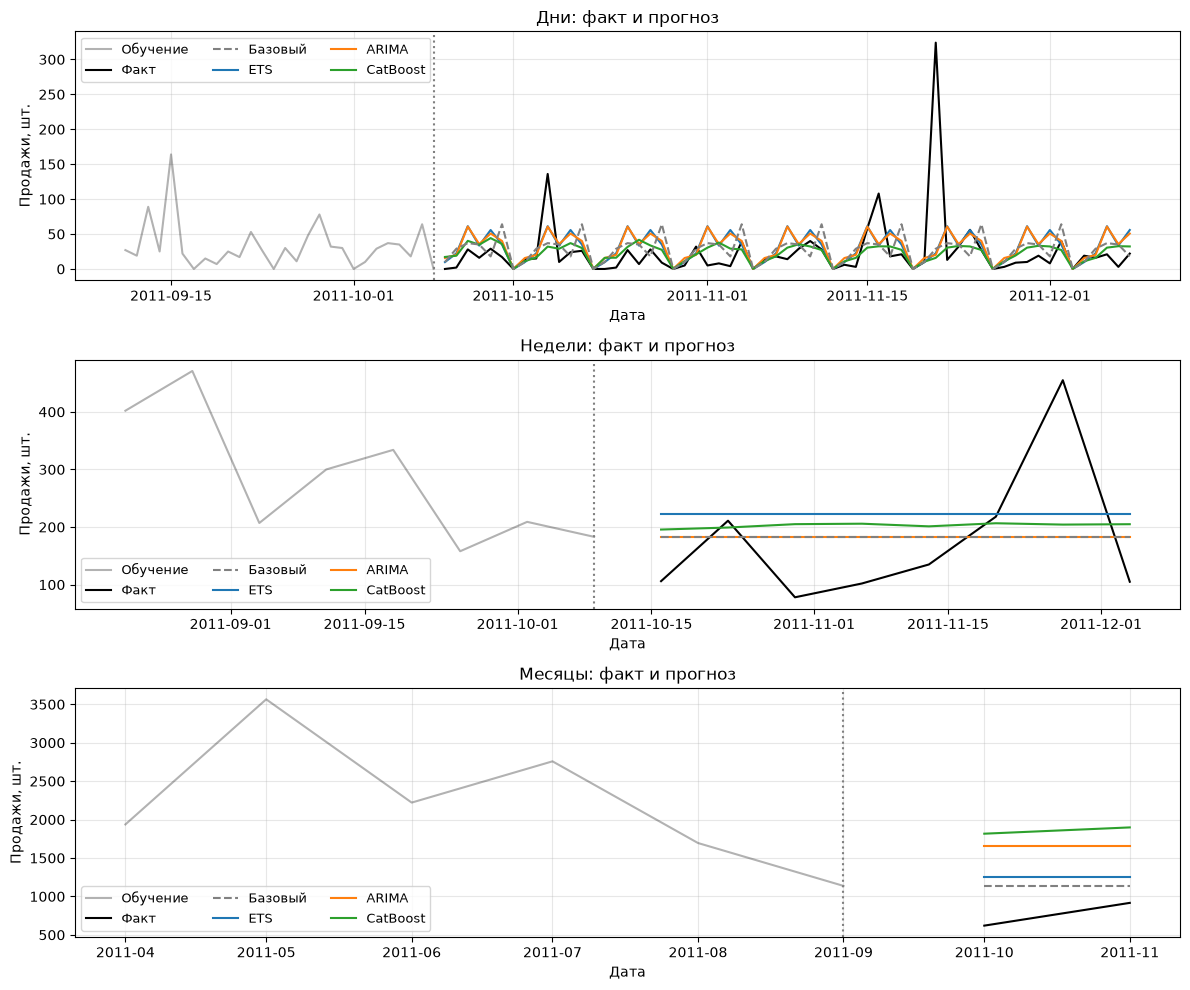

In [7]:
COLORS = {'Базовый': 'gray', 'ETS': 'tab:blue', 'ARIMA': 'tab:orange', 'CatBoost': 'tab:green'}


def plot_forecasts(splits, forecasts):
    fig, axes = plt.subplots(3, 1, figsize=(12, 10))
    for ax, (freq, (train, test)) in zip(axes, splits.items()):
        history = train.iloc[-{'Дни': 28, 'Недели': 8, 'Месяцы': 6}[freq]:]
        ax.plot(history.index, history, color='black', alpha=0.3, label='Обучение')
        ax.plot(test.index, test, color='black', label='Факт')
        for name, prediction in forecasts[freq].items():
            ax.plot(test.index, prediction, color=COLORS[name], label=name,
                    linestyle='--' if name == 'Базовый' else '-',
                    zorder=3 if name == 'Базовый' else 2)
        ax.axvline(train.index[-1], color='gray', linestyle=':')
        ax.set(title=f'{freq}: факт и прогноз', xlabel='Дата', ylabel='Продажи, шт.')
        ax.grid(alpha=0.3)
        ax.legend(ncol=3, fontsize=9)
    plt.tight_layout()
    plt.show()


plot_forecasts(splits, forecasts)


Все модели пропустили крупный заказ 21 ноября.
Дневная SARIMA сохраняет недельную сезонность.
Недельная ARIMA(0,1,0) без дрейфа повторяет последнее значение,
поэтому совпадает с базовым прогнозом. Месячная ARIMA(0,0,0)
с константой прогнозирует среднее. Все месячные прогнозы завышены.


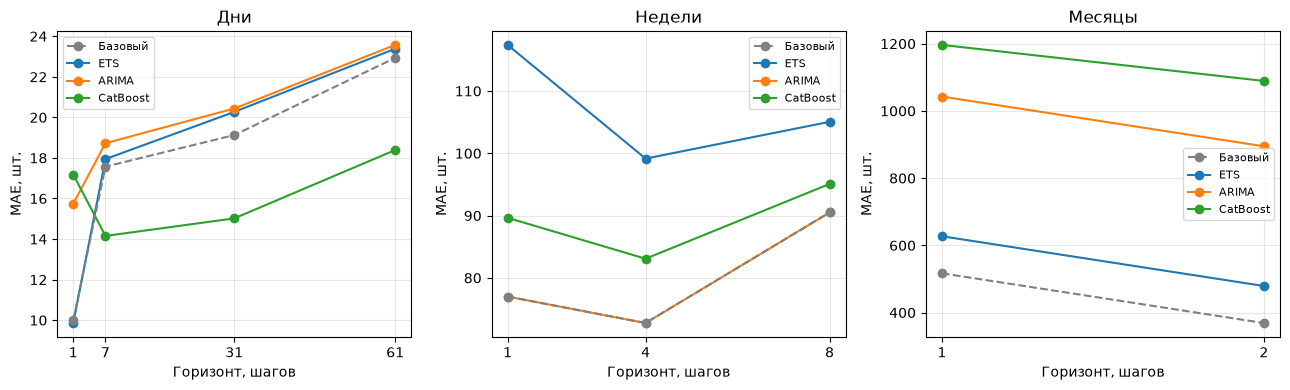

In [8]:
def plot_errors(metrics):
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    for ax, freq in zip(axes, HORIZONS):
        for name in COLORS:
            values = metrics.loc[metrics['Частота'].eq(freq) & metrics['Модель'].eq(name)]
            ax.plot(values['Горизонт'], values.MAE, marker='o', label=name,
                    color=COLORS[name], linestyle='--' if name == 'Базовый' else '-',
                    zorder=3 if name == 'Базовый' else 2)
        ax.set(title=freq, xlabel='Горизонт, шагов', ylabel='MAE, шт.')
        ax.set_xticks(HORIZONS[freq])
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


plot_errors(metrics)


### Шаг 5. Выводы

- На один день ETS немного лучше базового прогноза: MAE 9.86 шт.
  против 10.00. Оценка основана на одном дне.
- На 7, 31 и 61 день лучше CatBoost: MAE 14.15, 15.02 и 18.39 шт.
  У базового прогноза ошибки 17.57, 19.13 и 22.93 шт.
  На этих горизонтах CatBoost лучше и по RMSE.
- На 1, 4 и 8 недель ARIMA совпадает с базовым прогнозом:
  MAE 77.00, 72.75 и 90.50 шт. Они точнее ETS и CatBoost.
- На 1 и 2 месяца лучше последнее значение: MAE 517.00 и 369.00 шт.
  Среди трёх моделей лучше ETS: 627.19 и 479.19 шт.
- Ошибка не всегда растёт с горизонтом: в расчёт входят другие наблюдения.
  Все модели пропустили крупный оптовый заказ. Данных о будущих крупных
  заказах в признаках нет.

Месячные модели обучаются на 10 значениях и проверяются на двух.
После создания лагов у CatBoost остаётся 8 обучающих строк.
Результат подбора CatBoost зависит от seed. Его преимущество стоит проверить
на других периодах.
